In [1]:
import pandas as pd

#Install necessary packages
#!pip install xarray netcdf4


In [2]:
import xarray as xr
import matplotlib.pyplot as plt
import dask

# 1. Patch the broken Anaconda dask version string in memory
if getattr(dask, "__version__", "") == "unknown":
    dask.__version__ = "2025.11.0"

#Open the NetCDF file
ds = xr.open_dataset('data/SEAFLUX-OSB-CDR_V02R00_ATMOS_D20210101_C20210530.nc')

print(ds)

print(ds['air_temperature'].attrs)

<xarray.Dataset> Size: 133MB
Dimensions:            (time: 8, lat: 720, lon: 1440)
Coordinates:
  * time               (time) datetime64[ns] 64B 2021-01-01T01:30:00 ... 2021...
  * lat                (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.62 89.88
  * lon                (lon) float32 6kB 0.125 0.375 0.625 ... 359.4 359.6 359.9
Data variables:
    air_temperature    (time, lat, lon) float32 33MB ...
    specific_humidity  (time, lat, lon) float32 33MB ...
    wind_speed         (time, lat, lon) float32 33MB ...
    fill_missing_qc    (time, lat, lon) float32 33MB ...
Attributes: (12/39)
    Conventions:                CF-1.6
    title:                      NOAA Climate Data Record of Ocean Near-Surfac...
    source:                     SEAFLUX_Grid_D20210101.nc
    Metadata_Conventions:       CF-1.6, Unidata Dataset Discovery v2.0.2, NOA...
    standard_name_vocabulary:   CF Standard Name Table (v26, 08 November 2013)
    ID:                         SEAFLUX-OSB-CDR_V02R00_ATMOS_D

Let's plot an entire global heatmap of the data (let's do air temp and wind speed) by slicing it at the first timestep.

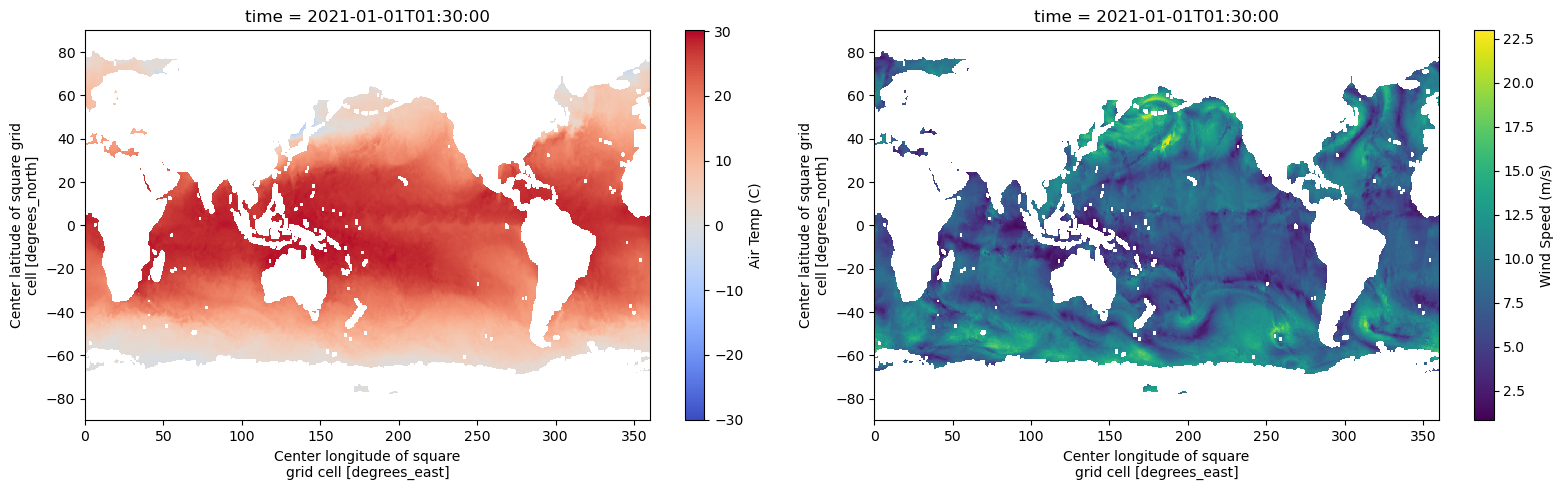

In [3]:
#Get rid of non-ocean pixels
ocean_only = ds.where(ds['fill_missing_qc'] <= 4)

#Select the first timestamp
fig, axes = plt.subplots(1, 2, figsize = (16, 5))

ocean_only['air_temperature'].isel(time = 0).plot(
    ax = axes[0], 
    cmap = 'coolwarm',
    cbar_kwargs = {'label': 'Air Temp (C)'}
)

ocean_only['wind_speed'].isel(time = 0).plot(
    ax = axes[1], 
    cmap = 'viridis',
    cbar_kwargs = {'label': 'Wind Speed (m/s)'}
)

plt.tight_layout()
plt.show()

Let's zoom in on a specific grid and get it's profile.

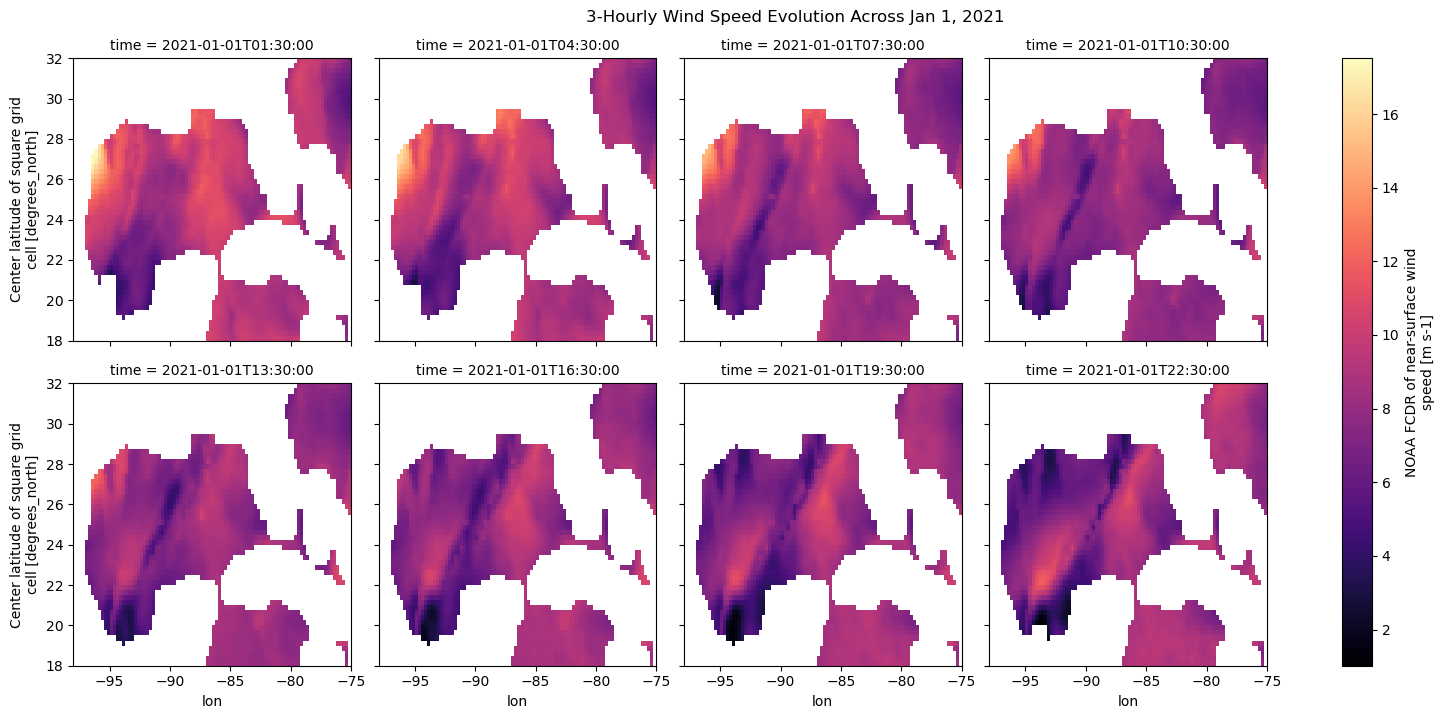

In [4]:
#Conver the latitude and longitude to -180-180 degrees rather than 0-360
ds = ds.assign_coords(lon = (((ds.lon + 180) % 360) - 180)).sortby(['lat', 'lon'])
ocean_only = ds.where(ds['fill_missing_qc'] <= 4)

#Slice the Gulf of Mexico and Western Atlantic
gulf_region = ocean_only.sortby(['lat', 'lon']).sel(
    lat = slice(18.0, 32.0),
    lon = slice(-98.0, -75.0)
)

#Plot all 8 time steps (every 3 hours) as a 2X4 grid of maps
gulf_region['wind_speed'].plot(
    col = 'time',
    col_wrap = 4,
    cmap = 'magma',
    figsize = (16, 7)
)

plt.suptitle('3-Hourly Wind Speed Evolution Across Jan 1, 2021', y = 1.02)
plt.show()

Below is a single latitude and longitude pair, plotted over time of an entire day across all 8 3-hour time intervals

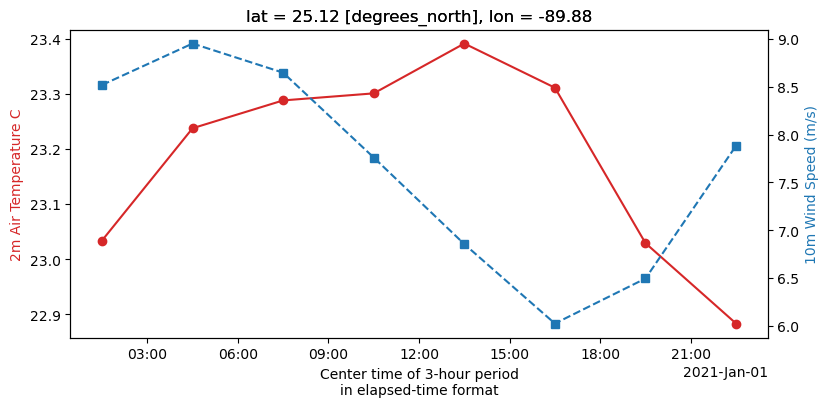

In [5]:
#Use method 'nearest' to snap to the closest 0.25 degree grid center
point_ts = ocean_only.sel(lat = 25.0, lon = -90.0, method = 'nearest')

fig, ax1 = plt.subplots(figsize = (9, 4))

#Plot air temp across all 8 time-steps
point_ts['air_temperature'].plot(
    ax = ax1,
    color = 'tab:red',
    marker = 'o',
    label = 'Air Temperature'
)
ax1.set_ylabel('2m Air Temperature C', color = 'tab:red')

#Plot wind speed on a secondary y-axis
ax2 = ax1.twinx()
point_ts['wind_speed'].plot(
    ax = ax2,
    color = 'tab:blue',
    marker = 's',
    linestyle = '--', 
    label = 'Wind Speed (m/s)'
)
ax2.set_ylabel('10m Wind Speed (m/s)', color = 'tab:blue')

#plt.title('3-Hourly Cycle at (25.0 N, 90.0 W) on Jan 1, 2021')
plt.show()

Let's convert our cubed data to a single python dataframe by slicing it.

In [6]:
df_gulf = (
    gulf_region[['wind_speed', 'air_temperature', 'specific_humidity']].
    to_dataframe()
    .dropna()       #Drop all land pixels
    .reset_index()  #Moves (time, lat, lon) from the MultiIndex into regular columns
)

print(f"Total valid ocean rows in region: {len(df_gulf)}")

df_gulf.head()

Total valid ocean rows in region: 19084


,time,lat,lon,wind_speed,air_temperature,specific_humidity
0,2021-01-01 01:30:00,18.125,-86.875,10.511770,26.973690,17.699768
1,2021-01-01 01:30:00,18.125,-86.625,10.512578,27.049864,17.880398
2,2021-01-01 01:30:00,18.125,-86.375,10.405862,27.128250,18.108166
3,2021-01-01 01:30:00,18.125,-86.125,10.235783,27.206537,18.304716
4,2021-01-01 01:30:00,18.125,-85.875,10.011560,27.287172,18.365255
